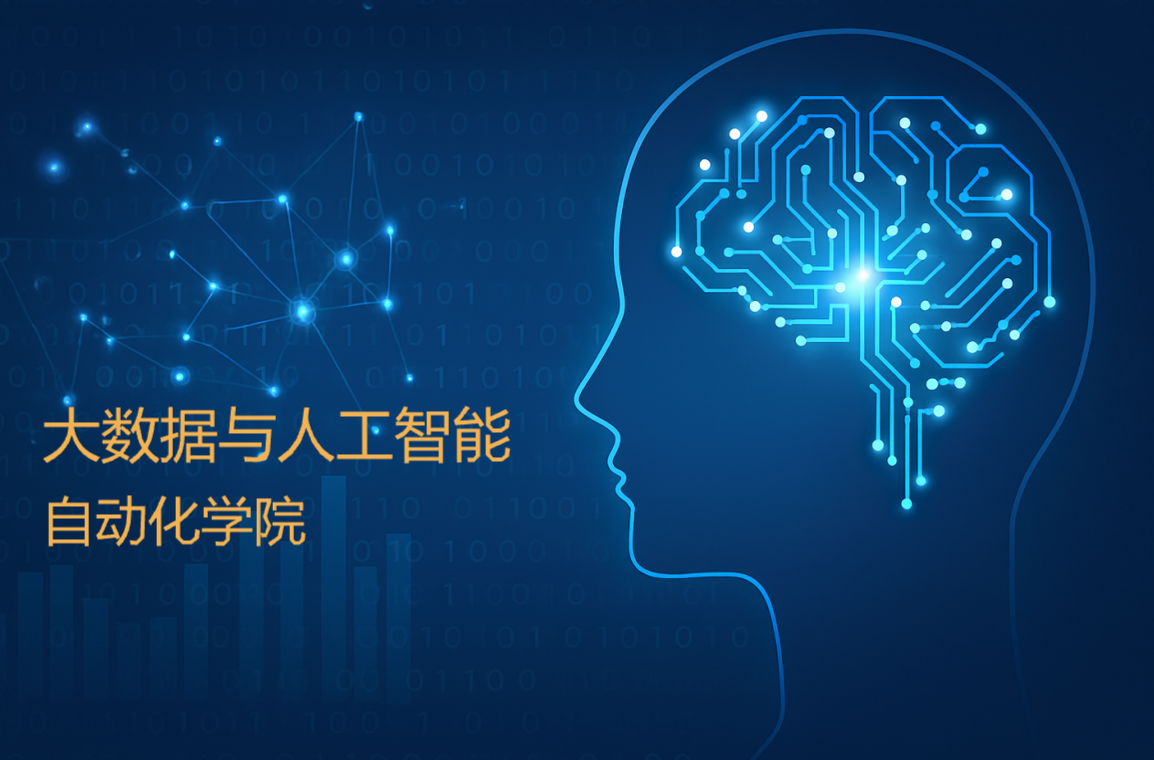

# 03-Transformers 高效微调 (PEFT) 篇

# 第3.1课：参数高效微调入门与 BitFit 实战

## 1\. 核心教学内容：以小博大的 BitFit

### 为什么全量微调“跑不动”？

在微调大模型时，最大的拦路虎是显存。以本课使用的 `Bloom-1b4-zh` (1.3B参数) 为例，虽然模型权重仅占约 **5.2GB**，但在全量训练时，你需要同时存储：

1. **模型权重** (5.2GB)
    
2. **梯度** (5.2GB)
    
3. 优化器状态 (如Adam需维护一阶、二阶动量，约10.4GB)
    
    合计约 21GB 显存。这意味着一张普通的 16G 或 24G 显卡很难跑得动更大的模型。
    
### 参数高效微调

- 在上述的情况下，**参数高效微调 (Parameter-efficient fine-tuning, PEFT)** 应运而生。
    
- 参数高效微调方法**仅对模型的一小部分参数**（这一小部分可能是模型自身的，也可能是外部引入的）进行训练，便可以为模型带来显著的性能变化，一些场景下甚至不输于全量微调，颇有一种**四两拨千斤**的感觉。
    
- 由于训练一小部分参数，极大地程度降低了训练大模型的算力需求，**不需要多机多卡，单卡即可完成**对一些大模型的训练。不仅如此，少量的训练参数对存储的要求同样降低了很多，大多数的参数高效微调方法只需要保存训练部分的参数，与动辄几十 GB 的原始大模型相比，**几乎可以忽略**。




### BitFit 的解决方案

BitFit（Bias-term Fine-tuning）是一种极简的微调策略。

- **原理**：Transformer 模型的每一层线性变换通常是 $y = Wx + b$。BitFit 策略是**冻结所有的矩阵权重 $W$，只训练偏置项 $b$**。
    
- **优势**：偏置项参数量极少（通常仅占总参数的 0.1% 以下），因此梯度和优化器状态占用的显存几乎可以忽略不计。
    
- **结果**：显存需求从 20GB+ 骤降至 **8GB** 左右，单卡即可轻松训练。
    


## 随堂作业

### 5.3.1 BitFit 微调方法的核心策略是？


### 1.1 模型下载新姿势：ModelScope

- 由于 Hugging Face 连接不便，我们使用国内的 **ModelScope (魔搭社区)** 进行模型下载。它被称为“更适合中国宝宝体质的 Hugging Face”。
- 如果用modelscope下载模型，可以不用学术资源加速，而且下载的模型使用transformers包一样可以加载。

#### 主网站
- https://www.modelscope.cn/home


#### 模型页面
- https://www.modelscope.cn/models


### 1.2\. 代码实战：下载与加载

### Step 1: 环境准备与模型下载

- 使用 `modelscope` 库（需要pip安装这个包）
- 下载 Bloom Llama-2 或 ChatGLM3 模型。

Python

In [ ]:
# 这里直接用命令行下载，可以成功
!modelscope download langboat/bloom-1b4-zh --cache_dir '/path2download'


* * *

## 2\. 完整代码实战（BitFit）

我们将手动实现参数冻结逻辑，无需依赖额外的 PEFT 库。

### Step 1: 导入环境与加载数据集

首先，我们需要加载处理对话数据所需的库和数据集。

Python

In [2]:
import os
# 必须在导入 torch 之前设置， 这样系统只会看到第一张 GPU，Trainer 就不会使用多 GPU。
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, DataCollatorForSeq2Seq, TrainingArguments, Trainer
import torch

# 加载本地保存的 Alpaca 中文数据集
# 数据集结构通常包含 instruction(指令), input(输入), output(输出)
ds = Dataset.load_from_disk("./data/alpaca_data_zh/")
print(f"数据集样本示例: {ds[0]}")

数据集样本示例: {'output': '以下是保持健康的三个提示：\n\n1. 保持身体活动。每天做适当的身体运动，如散步、跑步或游泳，能促进心血管健康，增强肌肉力量，并有助于减少体重。\n\n2. 均衡饮食。每天食用新鲜的蔬菜、水果、全谷物和脂肪含量低的蛋白质食物，避免高糖、高脂肪和加工食品，以保持健康的饮食习惯。\n\n3. 睡眠充足。睡眠对人体健康至关重要，成年人每天应保证 7-8 小时的睡眠。良好的睡眠有助于减轻压力，促进身体恢复，并提高注意力和记忆力。', 'input': '', 'instruction': '保持健康的三个提示。'}



### Step 2: 数据预处理（构建对话格式）

LLM 的训练本质是“文本接龙”。我们需要将问答拼接成模型能理解的格式。

Python

In [3]:
# 加载分词器
model_tag = "Langboat/bloom-1b4-zh"
model_path = "/3T/strange007/models/bloom-1b4-zh"
tokenizer = AutoTokenizer.from_pretrained(model_path)

def process_func(example):
    MAX_LENGTH = 256 # 设定最大长度，防止显存溢出
    input_ids, attention_mask, labels = [], [], []
    
    # 1. 拼接输入部分：Human: ... \n\nAssistant: 
    instruction = tokenizer("\n".join(["Human: " + example["instruction"], example["input"]]).strip() + "\n\nAssistant: ")
    
    # 2. 处理输出部分：回答 + 结束符
    response = tokenizer(example["output"] + tokenizer.eos_token)
    
    # 3. 拼接得到完整的输入 ID
    input_ids = instruction["input_ids"] + response["input_ids"]
    attention_mask = instruction["attention_mask"] + response["attention_mask"]
    
    # 4. 制作标签 (Labels)
    # 关键点：我们只希望模型学习“回答”，不希望它学习“提问”。
    # 所以将 Instruction 部分的 Label 设为 -100 (PyTorch中CrossEntropyLoss忽略的索引)
    labels = [-100] * len(instruction["input_ids"]) + response["input_ids"]
    
    # 5. 截断处理
    if len(input_ids) > MAX_LENGTH:
        input_ids = input_ids[:MAX_LENGTH]
        attention_mask = attention_mask[:MAX_LENGTH]
        labels = labels[:MAX_LENGTH]
        
    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }

# 应用处理函数到整个数据集
tokenized_ds = ds.map(process_func, remove_columns=ds.column_names)

OSError: Incorrect path_or_model_id: '/3T/strange007/models/bloom-1b4-zh'. Please provide either the path to a local folder or the repo_id of a model on the Hub.


### Step 3: 加载模型并应用 BitFit（核心步骤）

这是本节课最关键的代码。我们需要手动筛选出 Bias 参数并设为可训练。

Python

In [5]:
# 加载模型
model_tag = "Langboat/bloom-1b4-zh"
model_path = "/3T/strange007/models/bloom-1b4-zh"
model = AutoModelForCausalLM.from_pretrained(model_path, low_cpu_mem_usage=True)

# --- BitFit 核心逻辑 ---
num_param = 0
trainable_param = 0

# 遍历模型所有参数
for name, param in model.named_parameters():
    # 技巧：如果参数名字里不包含 "bias"，就冻结它
    if "bias" not in name:
        param.requires_grad = False
    else:
        # 如果是 bias，保留梯度计算（即参与训练）
        # 这一步其实不需要显式写 requires_grad=True，因为默认就是 True，但为了逻辑清晰可以理解为保留
        trainable_param += param.numel()
    num_param += param.numel()

print(f"总参数量: {num_param}")
print(f"可训练参数量 (Bias): {trainable_param}")
print(f"训练参数占比: {trainable_param / num_param:.4%}") 
# 预期占比极小，约 0.04%

总参数量: 1303111680
可训练参数量 (Bias): 544768
训练参数占比: 0.0418%



### Step 4: 配置训练参数并训练

显存大幅降低后，我们可以正常配置 Trainer。

Python

In [6]:
args = TrainingArguments(
    output_dir="./chatbot_bitfit",
    per_device_train_batch_size=1,     # 单卡 Batch Size
    gradient_accumulation_steps=8,     # 梯度累积，相当于 Batch Size = 8
    logging_steps=10,
    num_train_epochs=1,                # 演示仅训练 1 个 epoch
    save_steps=50,                     # 每50步保存一次
    learning_rate=3e-4                 # BitFit 只有 Bias，学习率通常可以稍大一点
)

trainer = Trainer(
    model=model,
    args=args,
    tokenizer=tokenizer,
    train_dataset=tokenized_ds,
    data_collator=DataCollatorForSeq2Seq(tokenizer=tokenizer, padding=True),
)

# 开始训练
trainer.train()

Step,Training Loss
10,2.798700
20,2.793500
30,2.591400
40,2.506700
50,2.535400
60,2.565200
70,2.393100
80,2.456600
90,2.316400
100,2.342000


TrainOutput(global_step=3357, training_loss=2.262768329805585, metrics={'train_runtime': 2771.3997, 'train_samples_per_second': 9.691, 'train_steps_per_second': 1.211, 'total_flos': 1.476411489067008e+16, 'train_loss': 2.262768329805585, 'epoch': 0.9999255342914588})


### Step 5: 模型推理验证

训练完成后，我们验证模型是否学会了像人一样回答问题。

Python

In [7]:
model = model.cuda() # 确保模型在 GPU 上

# 构造测试输入
text = "Human: 考试有哪些技巧？\n\nAssistant: "
ipt = tokenizer(text, return_tensors="pt").to(model.device)

# 生成回答
response = model.generate(**ipt, max_length=128, do_sample=True)
print(tokenizer.decode(response[0], skip_special_tokens=True))

Human: 考试有哪些技巧？

Assistant: 在面对考试时，考生需要掌握哪些技巧呢？以下是一些在考试中经常被提及的原则与策略：

1. 选择合适的策略

无论采取何种策略，考生都应该在准备考试时认真考虑考试策略的选择。只有选择适当的策略才能帮助您集中注意力保持专注，高效完成考试并且获得良好的成绩。考生可能需要考虑以下几个重要的策略：

- 分配时间与精力

考生需要制定一个合理的考试时间规划表，并分配好每部分内容的时间分配，以使其能顺利并有效率的完成



* * *

# 第3.2课：微调最终兵器 —— LoRA 实战

## 1\. 核心教学内容：LoRA (Low-Rank Adaptation)

### 为什么 LoRA 是目前的主流？

BitFit 虽然省显存，但因为它只调整偏置项，模型的表达能力上限较低，面对复杂任务可能效果一般。**LoRA** 完美平衡了“效果”和“效率”。

- 原理（矩阵分解）：
    
    假设模型原有的权重矩阵是 $W$（例如 $1024 \times 1024$）。
    
    LoRA 不直接更新 $W$，而是训练两个极小的旁路矩阵 $A$ 和 $B$：
    
    $$W_{new} = W + \Delta W = W + B \times A$$
    
    其中 $B$ 是 $1024 \times r$， $A$ 是 $r \times 1024$。如果秩 $r=8$，则参数量减少了百倍以上。

- **零推理延迟**：这是 LoRA 最大的杀手锏。训练结束后，我们可以把 $B \times A$ 的结果直接加回原权重 $W$ 中。这样推理时，模型结构和原来一模一样，没有任何额外的计算开销。

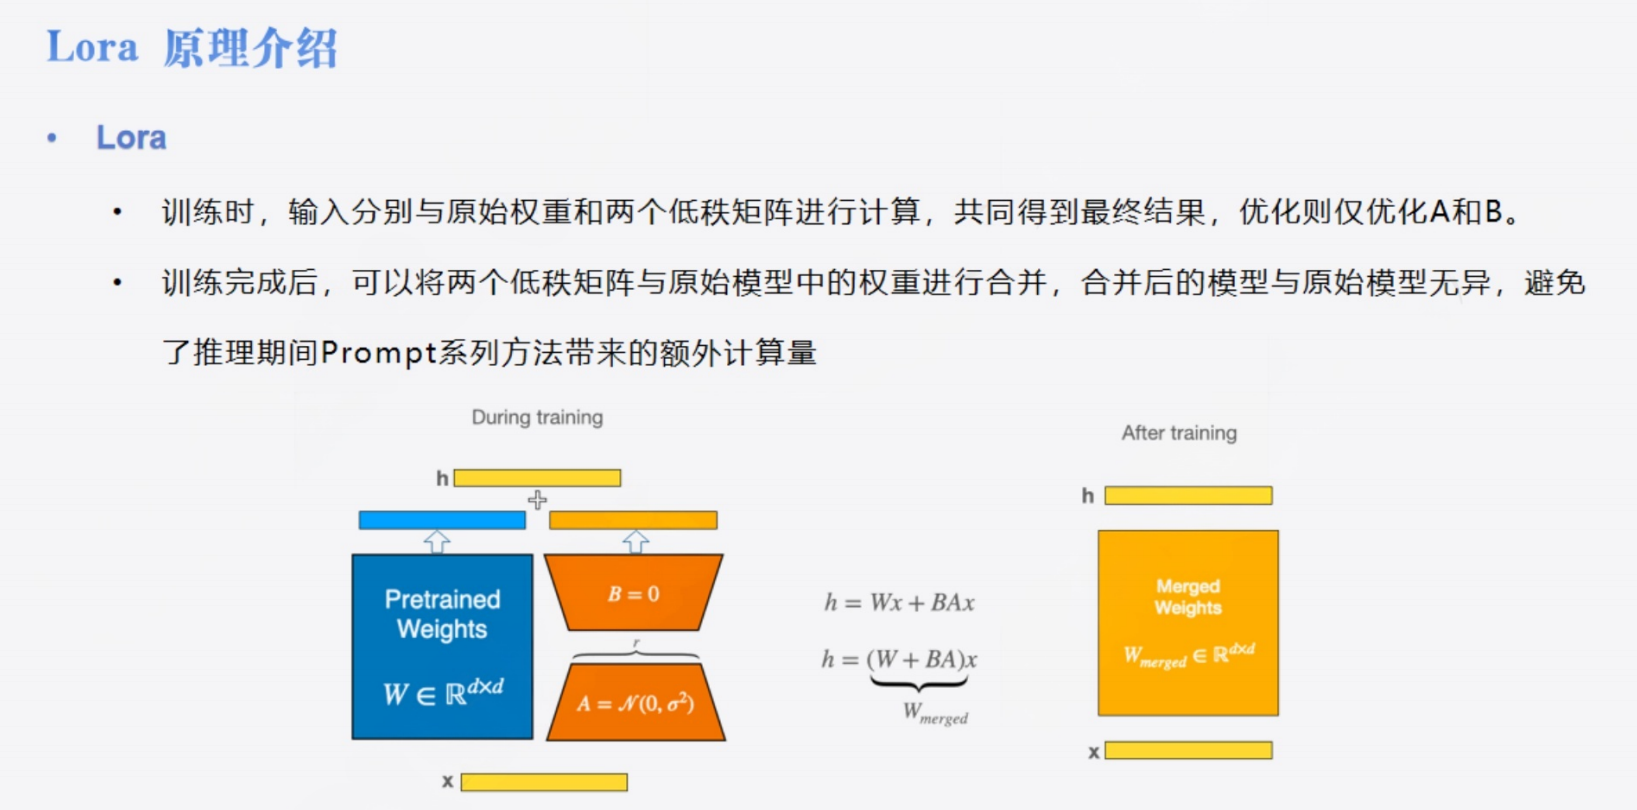

### 2\. LoRA 的魔法：低秩分解

LoRA 的核心思想是：**虽然原来的矩阵很大，但真正起作用、需要改变的核心信息其实并不多（低秩）。**

它把那个巨大的 $\Delta W$（$1024 \times 1024$）分解成了两个极瘦的矩阵 $B$ 和 $A$ 相乘。

- **矩阵 B**：形状是 $1024 \times r$
    
- **矩阵 A**：形状是 $r \times 1024$
    
- **秩 (Rank) $r$**：这是一个超参数，LoRA 的精髓就在于这个 $r$ 非常小（通常是 4, 8, 16, 32 等）。
    

**我们设定 $r=8$，来看看现在的参数量：**

1. **矩阵 B 的参数量**：$1024 \times 8 = 8,192$
    
2. **矩阵 A 的参数量**：$8 \times 1024 = 8,192$
    
3. **LoRA 总参数量**：$8,192 + 8,192 = 16,384$
    

* * *

### 3\. 为什么说减少了“百倍以上”？

现在我们来算一笔账，对比一下两种方式所需的训练参数量：

- **全量微调**：$1,048,576$
    
- **LoRA ($r=8$)**：$16,384$
    

缩减倍数计算：

$$\frac{1,048,576}{16,384} = 64 \text{ 倍}$$

在 $1024 \times 1024$ 这个例子中，参数减少了 **64倍**。

**❓ 为什么你看到的说法通常是“百倍甚至千倍”？**

因为现实中的大模型（如 Llama 3, GPT-4），它们的隐藏层维度（Hidden Size）远不止 1024。

假设一个现代大模型的维度是 4096（例如 Llama-7B 的维度）：

- **全量微调参数**：$4096 \times 4096 \approx \textbf{16,777,216}$ (1600万)
    
- **LoRA ($r=8$) 参数**：$(4096 \times 8) + (8 \times 4096) = \textbf{65,536}$ (6.5万)
    

缩减倍数：

$$\frac{16,777,216}{65,536} = \textbf{256 倍}$$

**结论**：模型越宽（维度越大），LoRA 节省参数的效果越恐怖。这就是为什么说能减少百倍以上的显存和存储需求。

* * *

### 4\. 为什么叫“零推理延迟”？(Zero Inference Latency)

虽然训练时我们将参数拆成了 $A$ 和 $B$ 两个矩阵，但在推理（使用模型）时，我们不需要分别计算。

**原理如下：**

1. **训练后**：我们得到了训练好的 $B$ 和 $A$。
    
2. **合并权重 (Merge)**：我们根据公式算出更新量 $\Delta W = B \times A$。虽然我们没有直接训练 $\Delta W$，但我们可以通过矩阵乘法把它算出来。算出来的 $\Delta W$ 也是 $1024 \times 1024$ 的矩阵。
    
3. 加回原模型：
    
    $$W_{final} = W_{original} + (B \times A)$$
    
4. **最终结果**：我们将 $W_{final}$ 保存下来。
    

对于使用者来说：

模型结构完全没变，还是原来那个 $1024 \times 1024$ 的大矩阵。推理时，数据只需要过这一个矩阵即可，不需要像适配器（Adapter）那样多过几个小层，因此推理速度和原版模型一模一样，没有任何额外开销。

### 总结

LoRA 之所以强大，是因为它利用了线性代数中矩阵乘法的特性：

用两个“瘦长”的矩阵相乘，可以还原出一个“巨大”方形矩阵的形状。通过只训练那两个“瘦长”矩阵，我们在保持改变模型能力的同时，极大地欺骗（节省）了显存和存储空间。



## 随堂作业

### 5.3.2 在 LoRA 配置中，r 参数代表什么？


* * *

## 3\. 完整代码实战（LoRA）

这里我们需要使用 HuggingFace 的 `peft` 库来实现。

### Step 1: 导入与数据处理

（数据处理逻辑与 BitFit 课程完全一致，为了保证代码独立性，这里再次给出，实际运行时如果已运行过上面代码可跳过 Process Func 定义）

Python

In [2]:
import os
# 必须在导入 torch 之前设置， 这样系统只会看到第一张 GPU，Trainer 就不会使用多 GPU。
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, DataCollatorForSeq2Seq, TrainingArguments, Trainer
# 引入 PEFT 库的关键组件
from peft import LoraConfig, TaskType, get_peft_model

model_tag = "Langboat/bloom-1b4-zh"
model_path = "/3T/strange007/models/bloom-1b4-zh"

# 1. 加载数据
ds = Dataset.load_from_disk("./data/alpaca_data_zh/")

# 2. 加载分词器
tokenizer = AutoTokenizer.from_pretrained(model_path)

# 3. 数据处理函数 (同上)
def process_func(example):
    MAX_LENGTH = 256
    instruction = tokenizer("\n".join(["Human: " + example["instruction"], example["input"]]).strip() + "\n\nAssistant: ")
    response = tokenizer(example["output"] + tokenizer.eos_token)
    input_ids = instruction["input_ids"] + response["input_ids"]
    attention_mask = instruction["attention_mask"] + response["attention_mask"]
    labels = [-100] * len(instruction["input_ids"]) + response["input_ids"]
    if len(input_ids) > MAX_LENGTH:
        input_ids = input_ids[:MAX_LENGTH]
        attention_mask = attention_mask[:MAX_LENGTH]
        labels = labels[:MAX_LENGTH]
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}

tokenized_ds = ds.map(process_func, remove_columns=ds.column_names)

Map:   0%|          | 0/26858 [00:00<?, ? examples/s]


### Step 2: 加载模型并配置 LoRA（核心步骤）

#### --- LoRA 配置 ---
- 教学重点：如何找到 target_modules？
- 不同的模型（BERT, GPT, LLaMA, Bloom）的 Attention 层命名不同。
- 我们可以先 print(model) 看看结构，Bloom 模型中 Attention 的核心层叫 "query_key_value"

Python

In [5]:
# 加载基座模型
model_tag = "Langboat/bloom-1b4-zh"
model_path = "/3T/strange007/models/bloom-1b4-zh"
model = AutoModelForCausalLM.from_pretrained(model_path)

from transformers import AutoModelForCausalLM

# 1. 加载模型
model = AutoModelForCausalLM.from_pretrained("/3T/strange007/models/bloom-1b4-zh")

# 2. 打印结构
print(model)


trainable params: 95,225,856 || all params: 1,398,337,536 || trainable%: 6.8099


In [ ]:
config = LoraConfig(
    task_type=TaskType.CAUSAL_LM, 
    # 目标模块：使用正则匹配 Bloom 模型中的 Attention 层
    # target_modules=".*\.1.*query_key_value", 
    target_modules=r".*\.1.*query_key_value",
    # r (秩): 决定了旁路矩阵的大小，通常 8, 16, 32 效果就很好
    r=8, 
    # lora_alpha: 缩放系数，通常设为 r 的 2倍或 4倍，用于控制新增权重的更新幅度
    lora_alpha=32, 
    # modules_to_save: 除了 LoRA 层，你可能还想训练 Embedding 层（可选）
    modules_to_save=["word_embeddings"] 
)

# 将模型包装成 PeftModel
model = get_peft_model(model, config)

# 打印模型结构，你会发现 Linear 层被替换成了 LoraLayer
model.print_trainable_parameters()
# 输出示例：trainable params: 2,xxx,xxx || all params: 1,xxx,xxx,xxx || trainable%: 0.18%

### 上面代码分析

在常规训练中，我们通常会对**每一层**都注入 LoRA，但这段代码通过正则限制，**只对第 1 层**进行了注入。

下面我结合你提供的模型结构（`BloomForCausalLM`）详细拆解这个原理。

### 1\. 模型参数的“全名”长什么样？

虽然你看到的 `print(model)` 结构是层级化的，但在代码底层（PyTorch），每一个模块都有一个**唯一的“全路径名”**。

根据你提供的模型结构：

Plaintext

```
(h): ModuleList(
  (0-23): 24 x BloomBlock( ...
    (self_attention): BloomAttention(
      (query_key_value): Linear(...)
```

Bloom 模型有 24 层（索引 0 到 23）。

第 0 层的 Attention 模块全名是：

transformer.h.0.self_attention.query_key_value

第 1 层的 Attention 模块全名是：

transformer.h.1.self_attention.query_key_value

...以此类推到第 23 层。

### 2\. 正则表达式拆解：`r".*\.1.*query_key_value"`

`peft` 库的 `target_modules` 参数支持正则表达式匹配。当它遍历模型中所有模块名称时，会拿这个正则去匹配。

我们来拆解 `r".*\.1.*query_key_value"` 的含义：

<table><tbody><tr><td><p><strong>正则符号</strong></p></td><td><p><strong>含义</strong></p></td><td><p><strong>匹配示例</strong></p></td></tr><tr><td><p><code>.*</code></p></td><td><p>匹配任意字符（0次或多次）</p></td><td><p>匹配前面的 <code>transformer.h</code></p></td></tr><tr><td><p><code>\.</code></p></td><td><p><strong>转义点号</strong>。因为 <code>.</code> 在正则里代表任意字符，所以要用 <code>\.</code> 表示“我只要一个真正的点”。</p></td><td><p>匹配路径中的分隔符 <code>.</code></p></td></tr><tr><td><p><code>1</code></p></td><td><p><strong>数字 1</strong>。这是最关键的部分！</p></td><td><p><strong>匹配层索引为 1 的层</strong></p></td></tr><tr><td><p><code>.*</code></p></td><td><p>匹配任意字符（0次或多次）</p></td><td><p>匹配中间的 <code>.self_attention.</code></p></td></tr><tr><td><p><code>query_key_value</code></p></td><td><p>匹配具体的模块名</p></td><td><p>匹配 <code>query_key_value</code></p></td></tr></tbody></table>

总结：

这个正则的意思是：“我不管前面是什么，后面是什么，只要路径里包含 .1 且名字包含 query_key_value 的模块，我就要对它进行微调。”

### 3\. 为什么要这样写？（`\.1` 的作用）

**作用：** 它是为了**过滤**。

- **如果是** `transformer.h.0...`：正则里要求有 `1`，这里是 `0`，**不匹配**。LoRA 不会注入第 0 层。
    
- **如果是** `transformer.h.1...`：正则匹配成功！**LoRA 会注入第 1 层**。
    
- **如果是** `transformer.h.12...`：虽然有 `1`，但正则写的是 `\.1`（点后紧跟1），且后面通常跟点。如果正则不够严谨（比如没写点），可能会误匹配到 10-19 层。但在这里，主要是为了演示**只选中第 1 层**。
    

### 4\. 为什么要演示这种写法？

在实际生产训练中，我们通常不会只训练第 1 层。这段代码通常出现在**教程**或**实验**中，目的有三个：

1. **展示灵活性**：证明 `peft` 库非常强大，不仅能指定模块名，还能精确指定**第几层的模块**。
    
2. **快速验证**：只训练一层，参数量极少，训练速度极快，甚至不需要 GPU 也能跑通流程，适合教学演示。
    
3. **对比实验**：研究人员可能想知道，“如果我只微调中间层，或者只微调最后几层，效果会有什么不同？”这时候正则写法就非常有用了。
    

### 5\. 如果你想正常训练（训练所有层）

如果你是想认真训练一个效果好的模型，而不是做实验，你应该去掉那个 `\.1` 的限制，让它匹配所有层。

**常规写法（推荐）：**

Python

```
# 方式一：直接指定名字（最常用，会自动匹配所有层）
target_modules=["query_key_value"]

# 方式二：正则匹配所有层
target_modules=r".*query_key_value" 
```

**对比效果：**

- **你的写法 (**`.*\.1.*`)：只训练第 1 层，可训练参数极少（几万或几十万）。
    
- **常规写法 (**`["query_key_value"]`)：训练 0-23 所有层，可训练参数量翻 24 倍。


### Step 3: 训练 LoRA 模型

由于 LoRA 大幅减少了可训练参数，显存占用极低，训练速度也很快。

Python

In [6]:
args = TrainingArguments(
    output_dir="./chatbot_lora",
    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,
    logging_steps=10,
    num_train_epochs=1,
    save_steps=50,
    learning_rate=1e-4  # LoRA 的学习率通常比全量微调大一点点
)

trainer = Trainer(
    model=model,
    args=args,
    tokenizer=tokenizer,
    train_dataset=tokenized_ds,
    data_collator=DataCollatorForSeq2Seq(tokenizer=tokenizer, padding=True),
)


/tmp/ipykernel_2181382/2820280292.py:11: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


In [7]:

trainer.train()

Step,Training Loss
10,2.712300
20,2.626600
30,2.589900
40,2.484300
50,2.422200
60,2.424000
70,2.309200
80,2.393400
90,2.218400
100,2.352500


TrainOutput(global_step=3358, training_loss=2.1971184359624885, metrics={'train_runtime': 2340.8311, 'train_samples_per_second': 11.474, 'train_steps_per_second': 1.435, 'total_flos': 1.4774698933714944e+16, 'train_loss': 2.1971184359624885, 'epoch': 1.0})


### Step 4: LoRA 模型推理与保存

PEFT 训练出的模型不是一个完整的模型，而是“基座模型权重” + “LoRA权重（很小）”。

Python

In [8]:
model = model.cuda()
ipt = tokenizer("Human: 考试有哪些技巧？\n\nAssistant: ", return_tensors="pt").to(model.device)
print(tokenizer.decode(model.generate(**ipt, max_length=128, do_sample=True)[0], skip_special_tokens=True))

# 保存 LoRA 权重
# 这只会保存几 MB 的文件（adapter_config.json 和 adapter_model.bin）
model.save_pretrained("./chatbot_lora_final") 

Human: 考试有哪些技巧？

Assistant: 在考试中，你可以使用一些技巧来帮助实现更高的成绩：

1. 准备充足：考试前要提前进行大量准备，充分了解考点，了解各科目的考试范围、考试内容、考试时间、复习提纲等，为考试做好充足、合理的准备。

2. 合理分配精力：考试时间很紧张，很多考生会感觉时间不够用，但是如果不能合理分配精力，很容易导致精力分配不灵活，影响发挥，因此在考试前要合理安排精力，做充足的准备。

3. 



* * *

### 总结与对比

<table><tbody><tr><td><p><strong>特性</strong></p></td><td><p><strong>BitFit</strong></p></td><td><p><strong>LoRA</strong></p></td></tr><tr><td><p><strong>显存占用</strong></p></td><td><p>极低</p></td><td><p>极低</p></td></tr><tr><td><p><strong>实现难度</strong></p></td><td><p>极简 (仅需 PyTorch)</p></td><td><p>简单 (需 PEFT 库)</p></td></tr><tr><td><p><strong>可训练参数</strong></p></td><td><p>仅 Bias</p></td><td><p>低秩矩阵 A, B</p></td></tr><tr><td><p><strong>表达能力</strong></p></td><td><p>较弱 (适合简单任务)</p></td><td><p><strong>强 (接近全量微调)</strong></p></td></tr><tr><td><p><strong>推理延迟</strong></p></td><td><p>无</p></td><td><p><strong>无 (可合并权重)</strong></p></td></tr><tr><td><p><strong>推荐场景</strong></p></td><td><p>资源极其受限的基线测试</p></td><td><p><strong>绝大多数微调场景的首选</strong></p></td></tr></tbody></table>



* * *

# 第3.3课：PEFT 进阶操作 (自定义适配与多适配器)

## 1\. 核心教学内容

本节课主要解决三个实际应用场景中的问题：

1. **自定义模型适配**：如果我的模型不在 PEFT 官方支持列表里（比如自己写的 `nn.Sequential`），如何使用 LoRA？
    
2. **多适配器管理**：如何在一个底座模型上同时加载多个 LoRA（例如一个负责任务A，一个负责任务B）并动态切换？这能极大节省显存。
    
3. **禁用适配器**：如何在不重新加载模型的情况下，临时获取原始模型的输出？
    

## 2\. 代码实战与拆解

### 场景一：自定义模型适配 LoRA

**问题**：直接对自定义模型使用 `get_peft_model` 会报错，因为 PEFT 不知道该把 LoRA 加在哪一层。 **解决**：必须显式指定 `target_modules`。

Python

In [1]:
import torch
from torch import nn
from peft import LoraConfig, get_peft_model, PeftModel

# 1. 定义一个简单的 Toy Model
#
net1 = nn.Sequential(
    nn.Linear(10, 10),  # 层索引: 0
    nn.ReLU(),          # 层索引: 1
    nn.Linear(10, 2)    # 层索引: 2
)

# 2. 尝试直接配置（会报错）
# config = LoraConfig() 
# model1 = get_peft_model(net1, config) -> 报错：Target modules not specified


### 为什么层名是 "0"？

首先看你的模型定义：

Python

```
net1 = nn.Sequential(
    nn.Linear(10, 10),  # 第 1 个元素
    nn.ReLU(),          # 第 2 个元素
    nn.Linear(10, 2)    # 第 3 个元素
)
```

`nn.Sequential` 的命名规则： 当你使用 `nn.Sequential` 并不给层起名字时，PyTorch 会**自动**按照它们添加的顺序，用**数字字符串**（"0", "1", "2", ...）作为每一层的名字。

我们可以通过打印模型的 `named_modules()` 来验证这一点：


In [2]:
# 打印模型每层的名字
for name, module in net1.named_modules():
    print(f"Name: '{name}' -> Module: {module}")

Name: '' -> Module: Sequential(
  (0): Linear(in_features=10, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=10, out_features=2, bias=True)
)
Name: '0' -> Module: Linear(in_features=10, out_features=10, bias=True)
Name: '1' -> Module: ReLU()
Name: '2' -> Module: Linear(in_features=10, out_features=2, bias=True)


In [3]:
# 3. 正确配置：手动指定 target_modules
# 这里我们要对第0层（第一个Linear）进行适配
#
config = LoraConfig(target_modules=["0"])

# 4. 成功注入
model1 = get_peft_model(net1, config)
print(model1)
# 输出可以看到第0层变成了 LoraLayer

PeftModel(
  (base_model): LoraModel(
    (model): Sequential(
      (0): lora.Linear(
        (base_layer): Linear(in_features=10, out_features=10, bias=True)
        (lora_dropout): ModuleDict(
          (default): Identity()
        )
        (lora_A): ModuleDict(
          (default): Linear(in_features=10, out_features=8, bias=False)
        )
        (lora_B): ModuleDict(
          (default): Linear(in_features=8, out_features=10, bias=False)
        )
        (lora_embedding_A): ParameterDict()
        (lora_embedding_B): ParameterDict()
        (lora_magnitude_vector): ModuleDict()
      )
      (1): ReLU()
      (2): Linear(in_features=10, out_features=2, bias=True)
    )
  )
)



### 场景二：多适配器加载与切换 (Multi-Adapter)

这是生产环境中非常实用的技巧。我们不需要加载两份大模型，只需要加载一份底座，然后挂载不同的轻量级 Adapter。

**Step 1: 准备工作 - 模拟训练并保存两个不同的 LoRA**

Python

In [4]:
# 定义底座模型
#
net2 = nn.Sequential(
    nn.Linear(10, 10),
    nn.ReLU(),
    nn.Linear(10, 2)
)

# 模拟训练 Adapter A (作用于第0层) 并保存
config1 = LoraConfig(target_modules=["0"])

model2 = get_peft_model(net2, config1)
model2.save_pretrained("./loraA") # 保存到 loraA 文件夹


In [5]:
# 模拟训练 Adapter B (作用于第2层) 并保存
config2 = LoraConfig(target_modules=["2"])
model2 = get_peft_model(net2, config2) # 重新包装以应用新配置
model2.save_pretrained("./loraB") # 保存到 loraB 文件夹

/3T/strange007/miniconda3/envs/teach/lib/python3.12/site-packages/peft/mapping_func.py:72: UserWarning: You are trying to modify a model with PEFT for a second time. If you want to reload the model with a different config, make sure to call `.unload()` before.
  warnings.warn(
/3T/strange007/miniconda3/envs/teach/lib/python3.12/site-packages/peft/tuners/tuners_utils.py:282: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(



**Step 2: 加载底座与第一个适配器**

Python

In [6]:
# 重新实例化纯净的底座模型
net2 = nn.Sequential(
    nn.Linear(10, 10),
    nn.ReLU(),
    nn.Linear(10, 2)
)

# 加载第一个适配器 loraA，并给它起个名字 adapter_name="loraA"
#
model2 = PeftModel.from_pretrained(net2, model_id="./loraA/", adapter_name="loraA")
print("当前激活适配器:", model2.active_adapter) # 输出: loraA

当前激活适配器: loraA



**Step 3: 加载第二个适配器并切换**

Python

In [7]:
# 使用 load_adapter 加载第二个适配器 loraB
#
model2.load_adapter("./loraB/", adapter_name="loraB")

# 查看当前状态（默认会自动切换到最新加载的适配器）
print("当前激活适配器:", model2.active_adapter) # 输出: loraB

# 手动切换回 loraA
#
model2.set_adapter("loraA")
print("切换后:", model2.active_adapter) # 输出: loraA

当前激活适配器: loraA
切换后: loraA



**Step 4: 验证切换效果** 为了证明真的切换了，我们可以手动修改一下权重，观察输出变化。

Python

In [8]:
# 构造输入数据
input_data = torch.arange(0, 10).view(1, 10).float()

# 强制修改一下 loraA 的权重，让效果明显一点
for name, param in model2.named_parameters():
    if "loraA" in name:
        param.data = torch.ones_like(param) # 把 loraA 的参数全变成 1

# 使用 loraA 推理
print("LoraA 输出:", model2(input_data))

# 切换到 loraB
model2.set_adapter("loraB")
# 使用 loraB 推理（结果应该不同，因为 loraB 还是初始化的权重）
print("LoraB 输出:", model2(input_data)) #

LoraA 输出: tensor([[ -14.1665, -306.6251]], grad_fn=<AddmmBackward0>)
LoraB 输出: tensor([[-1.1225,  0.8997]], grad_fn=<AddBackward0>)


### 为什么要手动修改权重？

Python

```
# 强制修改一下 loraA 的权重，让效果明显一点
for name, param in model2.named_parameters():
    if "loraA" in name:
        param.data = torch.ones_like(param) # 把 loraA 的参数全变成 1
```

- **背景**：当你刚初始化两个 LoRA 适配器（A和B）时，它们都是随机初始化的（或者B矩阵初始化为0）。这意味着此时模型加上适配器A，或者加上适配器B，输出结果可能相差无几，或者都和原模型一样。
    
- **目的**：为了证明 `set_adapter` 这个功能真的起作用了。
    
- **操作**：
    
    - 遍历模型所有参数。
        
    - 找到名字里带 `"loraA"` 的参数（也就是适配器 A 的权重）。
        
    - **暴力修改**：把这些参数的值全部强制设为 `1`。这在实际训练中是绝对不会做的，但这会让模型在使用 loraA 时的输出发生**剧烈变化**。
        

### 为什么要打印两次输出？

Python

```
# 使用 loraA 推理
print("LoraA 输出:", model2(input_data))

# 切换到 loraB
model2.set_adapter("loraB")
# 使用 loraB 推理
print("LoraB 输出:", model2(input_data))
```

- **第一次打印 (LoraA)**：
    
    - 此时处于 `loraA` 激活状态。
        
    - 由于我们刚才把 `loraA` 的权重全改成了 1，这个输出值会变得很大或很奇怪（比如全是很大的正数）。
        
    - **作用**：展示“被修改后的”效果。
        
- **切换 (**`set_adapter`)：
    
    - 这是本节课的核心 API。这一行代码让模型在内部把计算路径从“走A通路”切到了“走B通路”。
        
- **第二次打印 (LoraB)**：
    
    - 此时处于 `loraB` 激活状态。
        
    - `loraB` 我们**没有**去手动修改它，所以它还是初始化的状态（通常 LoRA 初始化时 B 矩阵为 0，所以输出应该和原模型一致）。
        
    - **作用**：展示“未被修改的、原始的”效果。
        

### 最终效果 (验证逻辑)

如果代码运行成功，你会看到类似这样的对比：

- **LoraA 输出**：`[10.5, 20.8, ...]` (因为权重被改成了1，数值很大)
    
- **LoraB 输出**：`[0.1, 0.2, ...]` (原始模型的正常输出)


### 场景三：禁用适配器 (Disable Adapter)

有时我们需要对比“微调后”和“微调前（原模型）”的效果，可以使用上下文管理器临时禁用。

Python

In [9]:
# 确保当前在使用 loraA
model2.set_adapter("loraA")
print("开启适配器:", model2(input_data))

# 使用 disable_adapter() 上下文管理器
with model2.disable_adapter():
    print("禁用适配器 (原模型输出):", model2(input_data))

# 退出 with 块后，自动恢复
print("恢复适配器:", model2(input_data))

开启适配器: tensor([[ -14.1665, -306.6251]], grad_fn=<AddmmBackward0>)
禁用适配器 (原模型输出): tensor([[-1.1225,  0.8997]])
恢复适配器: tensor([[ -14.1665, -306.6251]], grad_fn=<AddmmBackward0>)


## 随堂作业
### 5.3.3 在对自定义的 PyTorch 模型（如 nn.Sequential）使用 LoRA 时，为什么 target_modules 有时会写成 ["0"]？